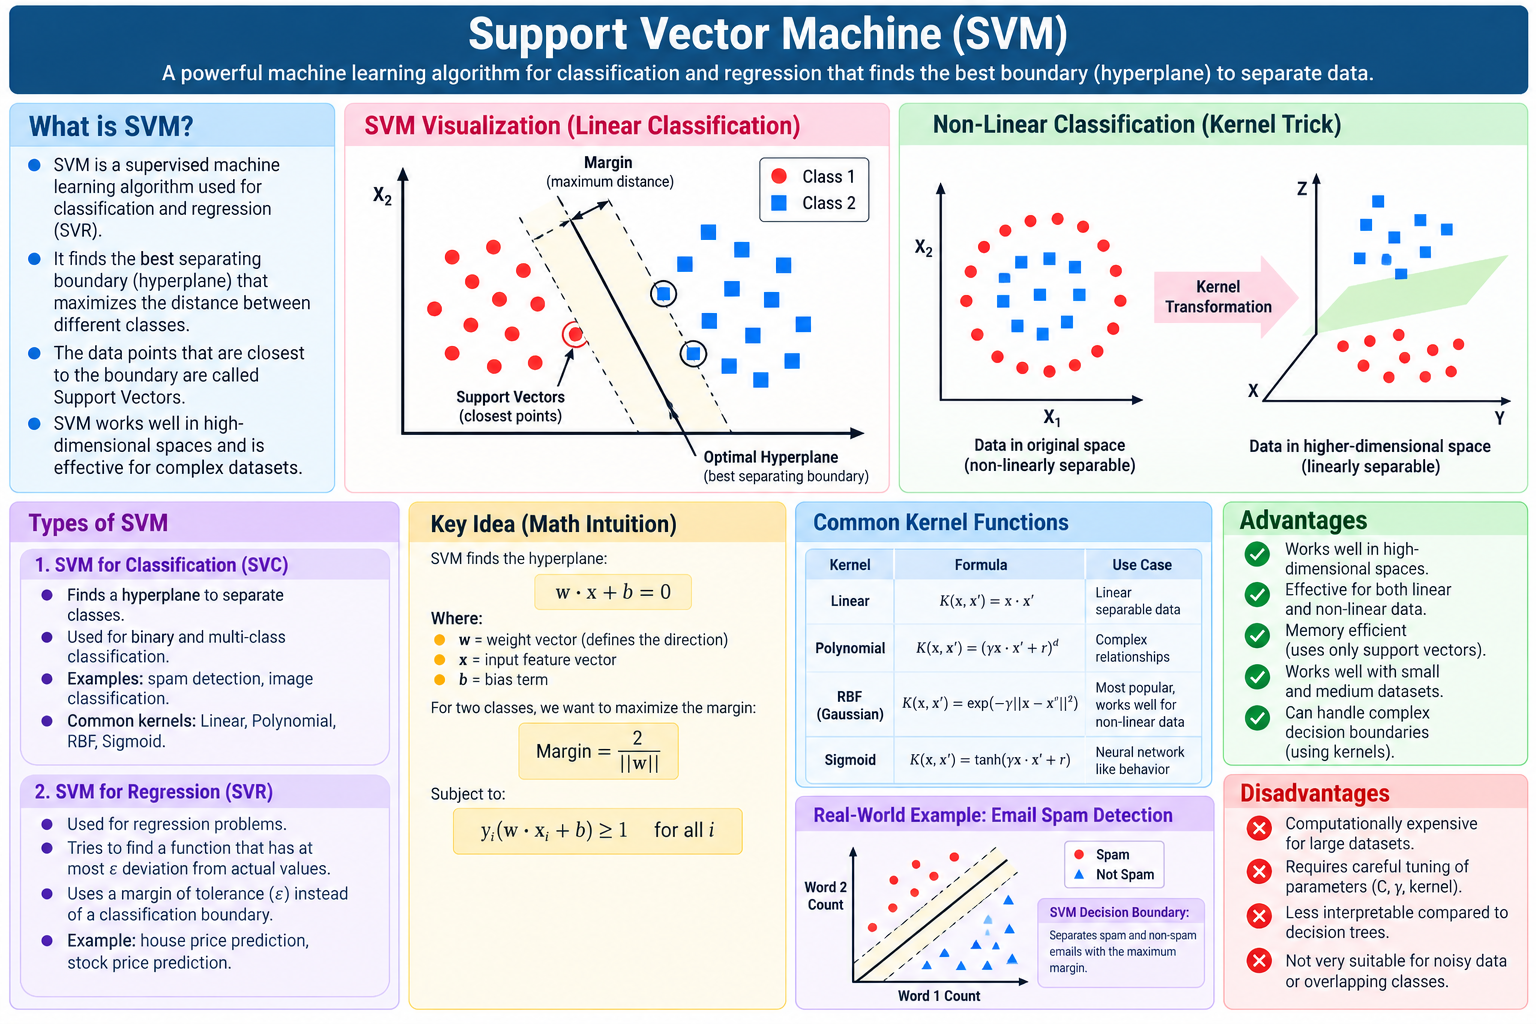

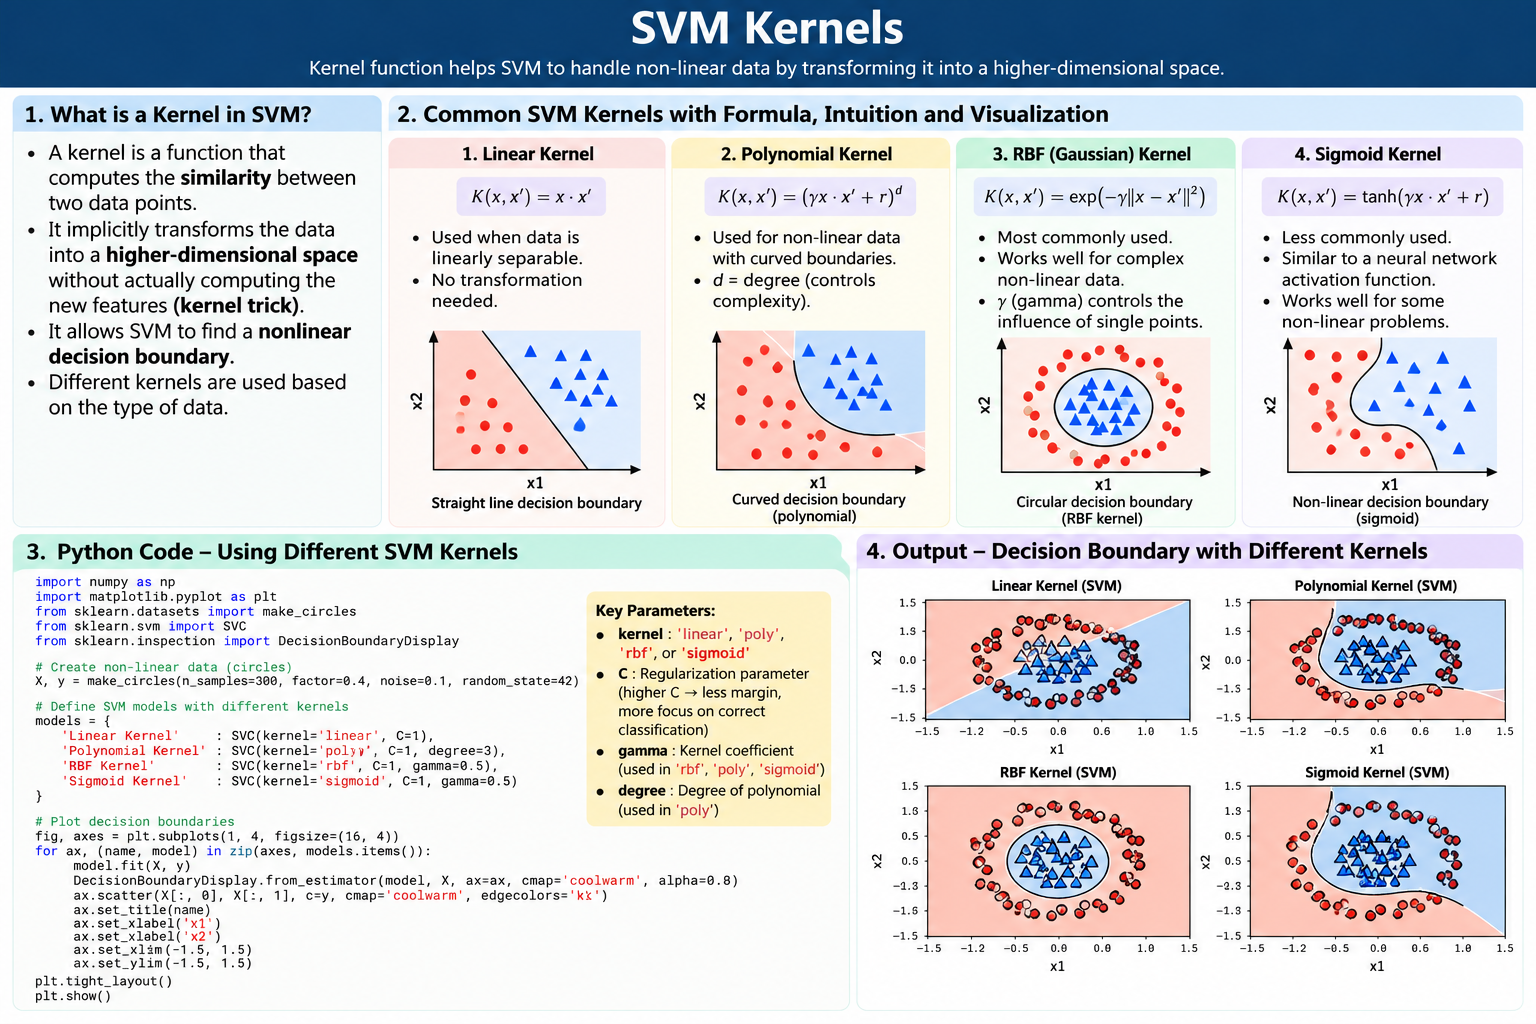

#**Implementation of Support Vector Machine (SVM) using a real dataset (Breast Cancer Dataset)**

**Step 1: Import Libraries**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

**Step 2: Load Real Dataset**

In [ ]:
data = load_breast_cancer()

# data.data: Numerical Value
# data.feature_names: Feature name
df = pd.DataFrame(data.data, columns=data.feature_names)

# Add the target (output) column to the DataFrame
# Target = 0 (Malignant - Cancerous)
# Target = 1 (Benign - Non-cancerous)
df['Target'] = data.target

df=df.sample(50).copy()

In [ ]:
df.shape

(50, 31)

In [ ]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
230,17.05,19.08,113.40,895.0,0.11410,0.15720,0.19100,0.10900,0.2131,0.06325,...,24.89,133.50,1189.0,0.1703,0.3934,0.50180,0.25430,0.3109,0.09061,0
129,19.79,25.12,130.40,1192.0,0.10150,0.15890,0.25450,0.11490,0.2202,0.06113,...,33.58,148.70,1589.0,0.1275,0.3861,0.56730,0.17320,0.3305,0.08465,0
431,12.40,17.68,81.47,467.8,0.10540,0.13160,0.07741,0.02799,0.1811,0.07102,...,22.91,89.61,515.8,0.1450,0.2629,0.24030,0.07370,0.2556,0.09359,1
240,13.64,15.60,87.38,575.3,0.09423,0.06630,0.04705,0.03731,0.1717,0.05660,...,19.05,94.11,683.4,0.1278,0.1291,0.15330,0.09222,0.2530,0.06510,1
436,12.87,19.54,82.67,509.2,0.09136,0.07883,0.01797,0.02090,0.1861,0.06347,...,24.38,95.14,626.9,0.1214,0.1652,0.07127,0.06384,0.3313,0.07735,1


**Step 3: Select Only Two Features (For Visualization)**

Decision boundaries can only be drawn in 2D, so we'll use only two features.

In [ ]:
X = df[['mean radius', 'mean texture','mean perimeter','mean area']]

y = df['Target']

**Step 4: Train-Test Split**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

**Step 5: Feature Scaling**

SVM works best when features are scaled.

In [ ]:
# Create an object of the StandardScaler class
scaler = StandardScaler()

# Learn the mean and standard deviation from the training data
# Then transform the training data so that:
# Mean = 0
# Standard Deviation = 1
X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

**Step 6: Train SVM Model**

In [ ]:
#svm = SVC(kernel='linear')
#svm = SVC(kernel='rbf')
#svm = SVC(kernel='sigmoid')
svm = SVC(kernel='poly', degree=3)
svm.fit(X_train, y_train)

SVC(kernel='poly')

**Step 7: Prediction**

In [ ]:
y_pred = svm.predict(X_test)

In [ ]:
y_pred

array([0, 1, 1, 1, 1, 1, 1, 1, 1, 1])

**Step 8: Accuracy**

In [ ]:
print("Accuracy :", accuracy_score(y_test, y_pred))

Accuracy : 0.7


**Step 9: Confusion Matrix**

In [ ]:
print(confusion_matrix(y_test, y_pred))

[[0 2]
 [1 7]]


**Step 10: Classification Report**

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       0.78      0.88      0.82         8

    accuracy                           0.70        10
   macro avg       0.39      0.44      0.41        10
weighted avg       0.62      0.70      0.66        10



Step 11: Visualize Support Vectors & Decision Boundary

ValueError: X has 2 features, but SVC is expecting 4 features as input.

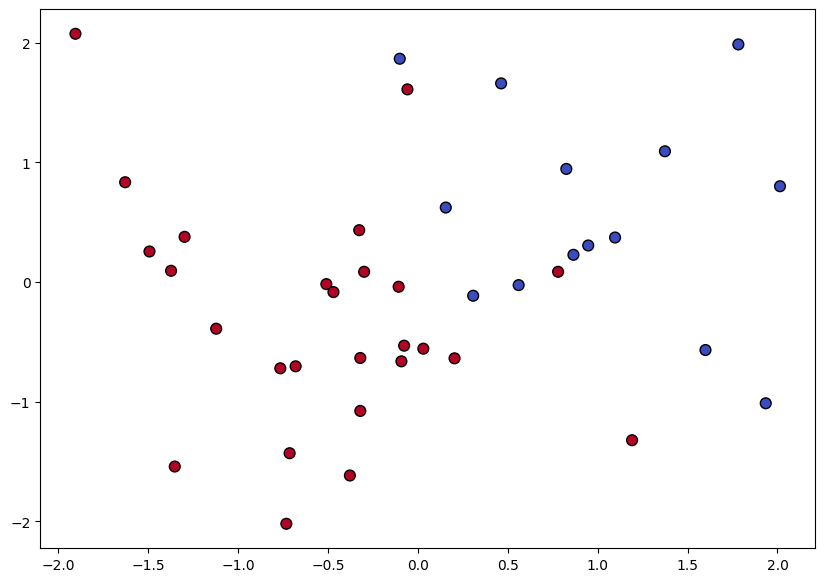

In [ ]:
plt.figure(figsize=(10,7))

# Plot data points
plt.scatter(
    X_train[:,0],
    X_train[:,1],
    c=y_train,
    cmap='coolwarm',
    edgecolors='k',
    s=60
)

# Create mesh grid
x_min, x_max = X_train[:,0].min()-1, X_train[:,0].max()+1
y_min, y_max = X_train[:,1].min()-1, X_train[:,1].max()+1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

Z = svm.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Decision Boundary
plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.2,
    cmap='coolwarm'
)

# Decision Line
plt.contour(
    xx,
    yy,
    Z,
    colors='black',
    linewidths=1
)

# Support Vectors
plt.scatter(
    svm.support_vectors_[:,0],
    svm.support_vectors_[:,1],
    s=200,
    facecolors='none',
    edgecolors='black',
    linewidths=2,
    label='Support Vectors'
)

plt.xlabel("Mean Radius (Scaled)")
plt.ylabel("Mean Texture (Scaled)")
plt.title("Linear SVM Decision Boundary")

plt.legend()

plt.show()

**Expected Accuracy**

Using the two selected features, a linear SVM typically achieves around 85–92% accuracy. If you use all 30 features from the dataset (without limiting to two for visualization), accuracy is usually 95–99%.